# Métodos jerárquicos


Construyen una organización anidada de clusters, usualmente representada mediante un **dendograma**

Pueden ser:
- aglomerativos: de puntos individuales hacia grupos mayores
- divisivos: de un grupo global hacia subdivisiones



--------------

## De particional a jerárquico

En los métodos de clustering particionales (como K-Means) buscamos una partición $C = \{C_1, \dots, C_k \}$. En los métodos jerárquicos construimos una secuencia de particiones anidadas.

### Ventaja

No es necesario fijar una única partición al iniciar el procedimiento. El resultado completo se presenta mediante un **dendograma** que puede cortarse a diferentes alturas para obtener distintos números de clústeres

-------

# 2 estrategias de agrupamiento jerárquico

| Aglomerativo  | Divisivo  |
| ------------  | --------  |
| abajo ---> arriba  | arriba --> abajo |
| Inicia con  m clústers unitarios: <br> {{$x^{(i)}$}, ...,{$x^{(i)}$} }  | Inicia con un macro-cluster: <br> $C^{(0)} = D^{(u)}_{train}$ |
| Fusiona repetidamente los dos clústeres más cercanos  | Divide recursivamente un clúster padre en dos clústeres hijos |
| Finaliza con un único clúster que contiene todos los datos | Puede continuar hasta obtener clústeres unitarios  |


----

# Idea general

En cada nivel tenemos una colección de clústeres

$$
H^{(t)} = \{ C_1^{(t)}, \dots, C_{k_t}^{(t)} \}
$$

El paso siguiente consiste en seleccionar el par

$$
(C_a, C_b) = \argmin d(C_r, C_s)
$$

- donde $C_r \neq C_s$

La estructura del algoritmo es la misma. Lo que cambia es cómo definimos la disimilitud $d(C_a,C_b)$ entre dos clústeres.


----

# Agrupamiento jerárquico aglomerativo

1. La regla de vinculación decide qué significa “cercanía” entre grupos. 
2. Cada fusión es irreversible en el procedimiento estándar. 
3. La secuencia completa de fusiones constituye el dendrograma.

-----

## Pseudocódigo

Entrada: $D^{(u)}_{train} = {x^{(i)}}^m_{i=1}$ y una regla de vinculación

1. Construir la matriz de disimilitudes entre todas las instancias
2. Inicializar cada instancia como un clúster unitario
3. Repetir:
    1. seleccionar los clústeres $C_a,C_b$ con menor disimilitud
    2. fusionarlos: $C_{a \cup b}$ ← $C_a \cup C_b$
    3. registrar la altura (disimilitud) de la fusión en el dendrograma
    4. actualizar las distancias entre $C_a \cup C_b$ y los clústeres restantes.
4. Detener cuando quede un único clúster.


--------

# Reglas de vinculación: ¿cómo medir la distancia entre clústeres?

Sea $d(x,z) = ∥x−z∥_2$

### Vinculación simple (single link)

- Compara los miembros más cercanos de ambos clústeres

$$
d_{mín}(C_a, C_b) = mín ∥ x^{(i)} -  x^{(j)}∥_2
$$

- Donde:
$x(i) \in C_a$ y $x(j) \in C_b$



------

## Vinculación completa (complete link)

- Compara los miembros más alejados de ambos clústeres.

$$
d_{mín}(C_a, C_b) = máx ∥ x^{(i)} -  x^{(j)}∥_2
$$

- Donde:
$x(i) \in C_a$ y $x(j) \in C_b$


-----

## Centroide

- La comparación se realiza entre representantes, no entre todos los pares de puntos.

- Representa cada clúster por su centroide $c_a$ y utiliza: 

$$
d(C_a, C_b) = ∥ c_a -  c_b ∥_2
$$


## Promedio

- Usa el promedio de las distancias entre los pares de instancias de ambos clústeres. 
- Busca un compromiso entre el comportamiento local de single link y el criterio más global de complete link.

----

# Ejemplo del jerárquico aglomerativo

- de scipy usamos:
    - linkage: para el método jerárquico
    - dendogram: para visualizarlo
    - fcluter: para asignarle un cluster a los puntos a partir de una cierta distancia

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import euclidean_distances
# from sklearn.metrics.pairwise import cosine_similarity
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
%matplotlib inline

plt.style.use("dark_background")

--------

In [6]:
datos = np.array([(1.0, 1.0), (1.2, 1.1),(0.8,0.9),(1.1,1.3),(1.0,0.8),(5.0,5.0),(5.2,4.8),(4.8,5.1),(5.1,5.2),(10,10)])

x = datos[: , 0]
y = datos[: , 1]

print(x)
print(y)

[ 1.   1.2  0.8  1.1  1.   5.   5.2  4.8  5.1 10. ]
[ 1.   1.1  0.9  1.3  0.8  5.   4.8  5.1  5.2 10. ]


------

#### Graficandolos

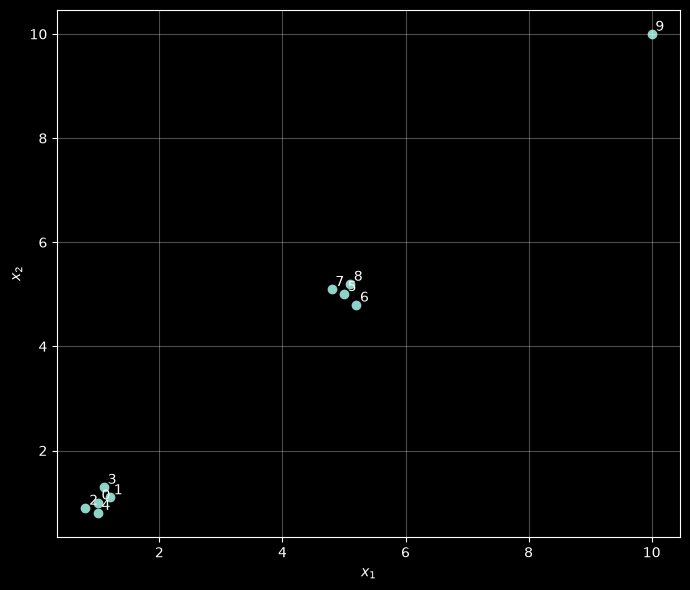

In [26]:
plt.figure(figsize=(7,6))
plt.scatter(x, y)
plt.grid(alpha=0.3)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.tight_layout()

for i in range(len(x)):
    plt.annotate(
        f"{i}",
        (x[i] + 0.06, y[i] + 0.06)
    )

---------

## matriz inicial dedistancias

In [28]:
# matriz_similitud = cosine_similarity(datos)
matriz_similitud = euclidean_distances(datos)
pd.DataFrame(matriz_similitud)

,0,1,2,3,4,5,6,7,8,9
0,0.000000,0.223607,0.223607,0.316228,0.200000,5.656854,5.663921,5.590170,5.869412,12.727922
1,0.223607,0.000000,0.447214,0.223607,0.360555,5.445181,5.448853,5.381450,5.658622,12.515990
2,0.223607,0.447214,0.000000,0.500000,0.223607,5.869412,5.879626,5.800000,6.081118,12.940247
3,0.316228,0.223607,0.500000,0.000000,0.509902,5.375872,5.390733,5.303772,5.586591,12.445883
4,0.200000,0.360555,0.223607,0.509902,0.000000,5.800000,5.800000,5.738467,6.014150,12.870120
5,5.656854,5.445181,5.869412,5.375872,5.800000,0.000000,0.282843,0.223607,0.223607,7.071068
6,5.663921,5.448853,5.879626,5.390733,5.800000,0.282843,0.000000,0.500000,0.412311,7.076722
7,5.590170,5.381450,5.800000,5.303772,5.738467,0.223607,0.500000,0.000000,0.316228,7.144928
8,5.869412,5.658622,6.081118,5.586591,6.014150,0.223607,0.412311,0.316228,0.000000,6.859300
9,12.727922,12.515990,12.940247,12.445883,12.870120,7.071068,7.076722,7.144928,6.859300,0.000000


--------

## Matriz de vinculación

In [34]:
# La matriz de vinculación se crea a partir de la matriz de similitud
mat_vincula = linkage(matriz_similitud, method="single")
pd.DataFrame(mat_vincula, columns=["Cluster A", "Cluster B", "Distancia", "Tamaño"])

/tmp/ipykernel_40523/1661970295.py:2: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  mat_vincula = linkage(matriz_similitud, method="single")


,Cluster A,Cluster B,Distancia,Tamaño
0,2.0,4.0,0.364022,2.0
1,1.0,3.0,0.397478,2.0
2,5.0,7.0,0.428372,2.0
3,0.0,10.0,0.488297,3.0
4,6.0,12.0,0.521941,3.0
5,8.0,14.0,0.629290,4.0
6,11.0,13.0,0.639006,5.0
7,15.0,16.0,16.505988,9.0
8,9.0,17.0,21.614758,10.0


-------

## Visualización de Dendrograma

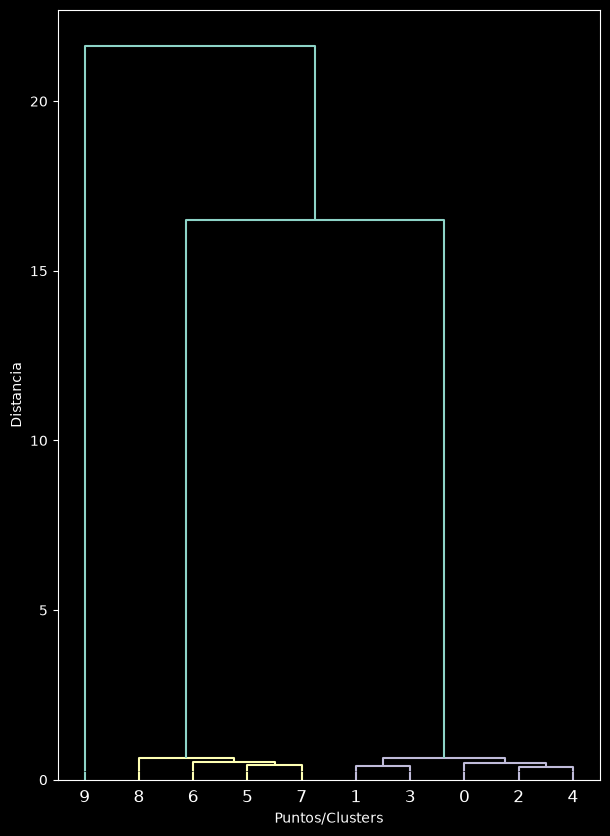

In [ ]:
plt.figure(figsize=(7, 10))
plt.xlabel("Puntos/Clusters")
plt.ylabel("Distancia")
plt.xticks(range(0, 20))
dendrogram(mat_vincula)
distancia_max = 0.25

plt.axhline(y=distancia_max, c="k", ls="--", lw=0.5)

-------------

https://github.com/CodigoMaquina/code/blob/main/machine_learning_python/clustering_jerarquico.ipynb

------

## Referencias

- Chandan K. Reddy y Bhanukiran Vinzamuri. “A Survey of Partitional and Hierarchical Clustering Algorithms”. En Charu C. Aggarwal y Chandan K. Reddy (eds.), Data Clustering: Algorithms and Applications, CRC Press / Taylor & Francis, 2014, cap. 4, especialmente §4.3.